In [17]:
import os
import shutil
import datetime
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive, files

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2,
    preprocess_input
)
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [18]:
drive.mount('/content/drive', force_remount=True)

BASE_PATH = '/content/drive/MyDrive/FaceMaskDetection'

DATA_PATH = os.path.join(BASE_PATH, 'data', 'images')
MODEL_PATH = os.path.join(BASE_PATH, 'models')

WITH_MASK_PATH = os.path.join(DATA_PATH, 'with_mask')
WITHOUT_MASK_PATH = os.path.join(DATA_PATH, 'without_mask')

os.makedirs(WITH_MASK_PATH, exist_ok=True)
os.makedirs(WITHOUT_MASK_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)

print("Google Drive connected successfully!")
print("Data Path:", DATA_PATH)
print("Model Path:", MODEL_PATH)
print("Folder structure created successfully!")

Mounted at /content/drive
Google Drive connected successfully!
Data Path: /content/drive/MyDrive/FaceMaskDetection/data/images
Model Path: /content/drive/MyDrive/FaceMaskDetection/models
Folder structure created successfully!


In [19]:
import os

print("Checking dataset in Google Drive...")

print("With-mask images:",
      len(os.listdir(WITH_MASK_PATH)))

print("Without-mask images:",
      len(os.listdir(WITHOUT_MASK_PATH)))

print("\nDataset verification completed!")

Checking dataset in Google Drive...
With-mask images: 1
Without-mask images: 1

Dataset verification completed!


In [20]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    DATA_PATH,
    target_size=(224, 224),
    color_mode="rgb",
    batch_size=32,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    DATA_PATH,
    target_size=(224, 224),
    color_mode="rgb",
    batch_size=32,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=42
)

print("Class indices:", train_generator.class_indices)
print("Training images:", train_generator.samples)
print("Validation images:", val_generator.samples)
print("Data generators are ready!")

Found 6044 images belonging to 2 classes.
Found 1510 images belonging to 2 classes.
Class indices: {'with_mask': 0, 'without_mask': 1}
Training images: 6044
Validation images: 1510
Data generators are ready!


In [21]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_tensor=Input(shape=(224, 224, 3))
)

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)

predictions = Dense(1, activation='sigmoid')(x)

model = Model(
    inputs=base_model.input,
    outputs=predictions
)

for layer in base_model.layers:
    layer.trainable = False

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/tmp/ipykernel_7643/403707415.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [22]:
EPOCHS = 10

MODEL_FILE = os.path.join(
    MODEL_PATH,
    "mask_detector_trained.keras"
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    MODEL_FILE,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

print("Starting model training...")

start_time = datetime.datetime.now()

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stopping, checkpoint]
)

end_time = datetime.datetime.now()

print("Training completed!")
print("Training duration:", end_time - start_time)
print("Model saved at:", MODEL_FILE)

Starting model training...
Epoch 1/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 560s 3s/step - accuracy: 0.9755 - loss: 0.0600 - val_accuracy: 0.9808 - val_loss: 0.0507
Epoch 2/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 608s 3s/step - accuracy: 0.9869 - loss: 0.0387 - val_accuracy: 0.9874 - val_loss: 0.0403
Epoch 3/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 511s 3s/step - accuracy: 0.9883 - loss: 0.0304 - val_accuracy: 0.9848 - val_loss: 0.0455
Epoch 4/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 583s 3s/step - accuracy: 0.9876 - loss: 0.0333 - val_accuracy: 0.9887 - val_loss: 0.0289
Epoch 5/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 631s 3s/step - accuracy: 0.9924 - loss: 0.0222 - val_accuracy: 0.9934 - val_loss: 0.0173
Epoch 6/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 517s 3s/step - accuracy: 0.9922 - loss: 0.0213 - val_accuracy: 0.9854 - val_loss: 0.0345
Epoch 7/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 525s 3s/step - accuracy: 0.9892 - loss: 0.0250 - val_accuracy: 0.9947 - val_loss: 0.0182
Epoch 8/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 530s 3s/step - accuracy: 0.993

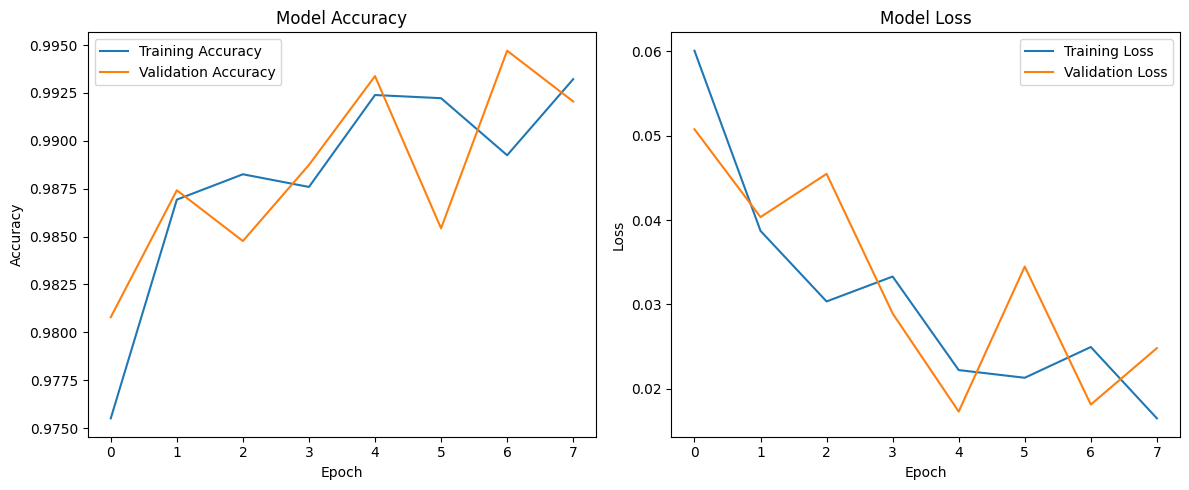

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

48/48 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.9934 - loss: 0.0173
Validation Loss: 0.017322443425655365
Validation Accuracy: 0.9933775067329407
48/48 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step

Classification Report:
              precision    recall  f1-score   support

   with_mask       0.99      0.99      0.99       745
without_mask       0.99      0.99      0.99       765

    accuracy                           0.99      1510
   macro avg       0.99      0.99      0.99      1510
weighted avg       0.99      0.99      0.99      1510



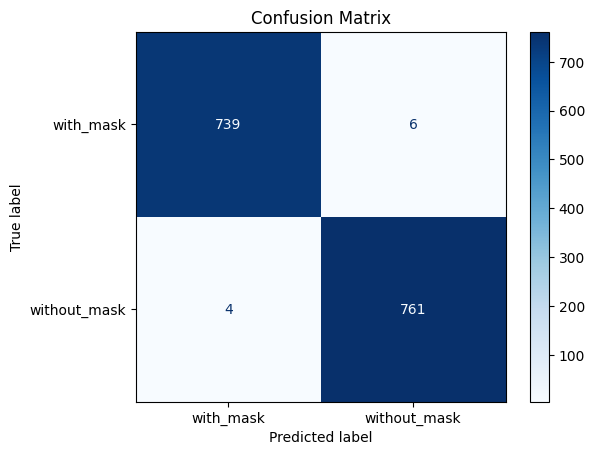

In [24]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

val_generator.reset()

loss, accuracy = model.evaluate(val_generator)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

val_generator.reset()

predictions = model.predict(val_generator)
predicted_classes = (predictions > 0.5).astype(int).flatten()

true_classes = val_generator.classes

class_labels = [
    label for label, index in sorted(
        val_generator.class_indices.items(),
        key=lambda item: item[1]
    )
]

print("\nClassification Report:")
print(
    classification_report(
        true_classes,
        predicted_classes,
        target_names=class_labels
    )
)

cm = confusion_matrix(true_classes, predicted_classes)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

display.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [25]:
MODEL_FILE = os.path.join(
    MODEL_PATH,
    "mask_detector_trained.keras"
)

model = tf.keras.models.load_model(MODEL_FILE)

print("Model loaded successfully!")

Model loaded successfully!


In [26]:
from tensorflow.keras.utils import load_img, img_to_array

def predict_mask(image_path):

    image = load_img(
        image_path,
        target_size=(224, 224)
    )

    image_array = img_to_array(image)
    image_array = np.expand_dims(image_array, axis=0)

    image_array = preprocess_input(image_array)

    prediction = model.predict(image_array, verbose=0)[0][0]

    if prediction < 0.5:
        label = "With Mask"
        confidence = (1 - prediction) * 100
    else:
        label = "Without Mask"
        confidence = prediction * 100

    plt.imshow(load_img(image_path))
    plt.axis('off')
    plt.title(f"{label} ({confidence:.2f}%)")
    plt.show()

    print("Prediction:", label)
    print("Confidence:", f"{confidence:.2f}%")

Upload an image to test the Face Mask Detection model:


Saving with_mask_30.jpg to with_mask_30.jpg


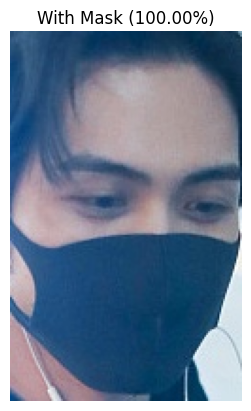

Prediction: With Mask
Confidence: 100.00%


In [28]:
print("Upload an image to test the Face Mask Detection model:")

uploaded_image = files.upload()

for filename in uploaded_image.keys():
    predict_mask(filename)

In [29]:
FINAL_MODEL_PATH = os.path.join(
    MODEL_PATH,
    "mask_detector_trained.keras"
)

model.save(FINAL_MODEL_PATH)

print("===================================")
print("FACE MASK DETECTION PROJECT")
print("===================================")
print("Model Architecture: MobileNetV2")
print("Image Input Size: 224 x 224")
print("Number of Epochs:", len(history.history['accuracy']))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Model Location:", FINAL_MODEL_PATH)
print("Project completed successfully!")

FACE MASK DETECTION PROJECT
Model Architecture: MobileNetV2
Image Input Size: 224 x 224
Number of Epochs: 8
Validation Accuracy: 99.34 %
Model Location: /content/drive/MyDrive/FaceMaskDetection/models/mask_detector_trained.keras
Project completed successfully!
